# 04 · Nonlinear (kernel) Granger causality between media coverage and search interest

Notebook 03 tested **linear** Granger causality. This notebook asks whether **nonlinear**
predictive links exist between MediaCloud coverage (MC) and Google Trends interest (GT),
in each direction, with the two constraint-based kernel methods reviewed and unified by
**Murphy & Benavoli (2026), "Constraint- and Score-Based Nonlinear Granger Causality
Discovery with Kernels", arXiv:2601.09579**:

| Method | Idea | Decision rule in the original papers |
|---|---|---|
| **KGC**, kernel Granger causality (Marinazzo, Pellicoro & Stramaglia, 2008) | project the effect on its own past in a kernel space, then correlate what is left with the new directions brought by the cause | correlations significant after Bonferroni ($\delta_f > 0$) |
| **lsNGC**, large-scale nonlinear Granger causality (Wismüller et al., 2021) | nonlinear features of each block (Gaussian radial basis functions around k-means centres), then compare least-squares fits with and without the cause | F-test, false discovery rate control |

KGC uses the squared-exponential (SE) kernel with the lengthscale heuristic of the paper
($l = 2\times$ number of inputs). It is also run with a polynomial kernel of degree 1, which
reduces it exactly to **linear** Granger causality, as a reference.

### What this notebook adds for campaign data

Both methods assume that no unobserved variable drives both series. Here one does: **the
campaign calendar** raises press coverage and searches at the same dates. So:

1. **Lags never cross seasons.** Each lagged value comes from the same campaign window.
2. **Season-swap surrogates.** Under the null, the cause series of each season is replaced
   by that of *another* season, aligned by day of the window. The surrogate keeps the
   cause's own dynamics and its campaign-shaped profile, but loses its day-to-day link
   with the effect. A link is retained only if the real cause does better than 199 such
   surrogates.
3. **Calendar conditioning (variant).** Day in the window and day of the week are added to
   both models, so that the cause must add information beyond a fixed calendar profile.
4. **Validation on simulations** with a known truth, including common drivers, before
   looking at real data.

**What remains out of reach.** A common driver whose timing changes from one year to the
next (a campaign launched on a different day each year, a celebrity announcement…) still
links both series within a season. Section 2 shows that no test here removes it. Results
are therefore evidence of **predictive links beyond a fixed campaign calendar**, not proof
of a direct causal effect.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "phc").exists())
sys.path.insert(0, str(ROOT / "src"))

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from phc.config import CAMPAIGNS, FIG_DIR, TAB_DIR
from phc.granger import load_daily
from phc import kernel_granger as K
from phc import simulate as S
from phc import transfer as T

# ---- parameters -----------------------------------------------------------
RECOMPUTE = False        # False: reuse results/cache/kernel_granger.joblib if it exists
N_JOBS = -1              # parallel workers (-1 = all cores)
N_SURR = 199             # season-swap surrogates, real data (p-value resolution 0.005)
N_SURR_SIM = 99          # surrogates, single simulated dataset per scenario
N_SURR_RATE = 39         # surrogates, rejection-rate study (resolution 0.025)
RATE_SEEDS = range(100)  # simulated datasets per scenario in the rejection-rate study
N_SEEDS = 10            # k-means initialisations in the lsNGC robustness check
N_SURR_BIG = 999         # surrogates in the weekly-cycle check (p-value resolution 0.001)
LAGS = (1, 2, 3, 5, 7)   # lag orders compared
START = max(LAGS)        # first target day of each season (same sample for every lag)
ALPHA = 0.05

CODES = ["DJ", "MB", "Mov", "OR"]
LABEL = {c: CAMPAIGNS[c].label for c in CODES}
DIRS = [("gt", "mc", "MC → GT"), ("mc", "gt", "GT → MC")]     # (effect, cause, label)
METHODS = {"kgc_lin": "Linear Granger", "kgc_se": "KGC (SE kernel)", "lsngc": "lsNGC"}

CACHE = ROOT / "results" / "cache" / "kernel_granger.joblib"
CACHE.parent.mkdir(parents=True, exist_ok=True)
cache = joblib.load(CACHE) if (CACHE.exists() and not RECOMPUTE) else {}


def cached(key, fn):
    """Compute fn() once and store the result in the cache file."""
    if key not in cache:
        t = time.time()
        cache[key] = fn()
        joblib.dump(cache, CACHE)
        print(f"[{key}] computed in {time.time() - t:.0f}s")
    else:
        print(f"[{key}] loaded from cache")
    return cache[key]


def strip(r):
    """Drop the arrays of surrogate statistics from a result dict."""
    return {k: v for k, v in r.items() if k != "nulls"}


def fmt_p(v):
    if np.isnan(v):
        return "–"
    if v < 0.001:
        return "<0.001"
    return f"{v:.3g}" if v < 0.1 else f"{v:.2f}"


pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. The two methods

Notation: $y$ is the effect at day $t$; $X$ holds its past values (restricted inputs);
$X_a$ holds the past values of the cause $a$, and $Z=[X, X_a]$. Series are standardised.

**KGC.** With the centred kernel matrix $K(X,X)$, let $P$ project on its range
(eigenvalues $>10^{-6}\lambda_{max}$). The part of $y$ that its own past cannot explain is
$e=(I-P)y$. The cause brings the new directions $w_i$, eigenvectors of
$\tilde K=(I-P)K(Z,Z)(I-P)$. With $r_i=\mathrm{corr}(e,w_i)$, the filtered index is
$\delta_f=\sum r_i^2$ over the correlations significant after Bonferroni, and
$\delta=\sum_i r_i^2$ (all directions) is the share of the unexplained variance captured by
the cause. The surrogate test uses $\delta$.

**lsNGC.** k-means places $c_f=25$ centres in the space of $X$ and $c_g=5$ in the space of
$X_a$. Each observation is mapped to normalised Gaussian activations around these centres
(width = mean distance between centres), $f(X)$ and $g(X_a)$. The restricted model regresses
$y$ on $f(X)$; the unrestricted model on $[f(X), g(X_a)]$ (an additive model). F-test on the
added block, and $\delta = 1-SSR_u/SSR_r$ for the surrogate test.

**Multiple testing.** Each method runs 8 tests per variant (4 campaigns × 2 directions).
Parametric tests are corrected as in their papers (KGC: Holm across the 8 tests, on top of
its internal Bonferroni; lsNGC: Benjamini–Hochberg). Surrogate p-values are Holm-adjusted.

## 2. Validation on simulated data

Four systems of 11 seasons × 91 days with a known truth (`src/phc/simulate.py`):

| Scenario | Truth |
|---|---|
| Nonlinear MC → GT | GT depends on the **square** of yesterday's MC: no linear correlation at all |
| Independent | no link |
| Common driver, fixed timing | no direct link; a campaign pulse on the same days every year drives both |
| Common driver, timing varies | no direct link; the pulse moves by up to ±15 days from year to year |

### 2.1 One simulated dataset per scenario

In [2]:
def sim_one(scenario, effect, cause, label, n_surr, seed=1):
    df = S.SCENARIOS[scenario](seed=seed)
    r = K.run_tests(df, effect, cause, m=3, start=START, n_surrogates=n_surr, seed=seed + 100)
    return {"scenario": scenario, "direction": label, "truth": S.TRUTH[scenario][label],
            "seed": seed, **strip(r)}


sim = cached("sim_single", lambda: pd.DataFrame(Parallel(n_jobs=N_JOBS)(
    delayed(sim_one)(sc, e, c, lab, N_SURR_SIM) for sc in S.SCENARIOS for e, c, lab in DIRS)))

TESTS = [(f"{k}_{t}", f"{v}\n({'paper test' if t == 'p_param' else 'surrogates'})")
         for k, v in METHODS.items() for t in ("p_param", "p_surr")]
sim_view = sim[["scenario", "direction", "truth"] + [c for c, _ in TESTS]]
sim_view.to_csv(TAB_DIR / "kernel_granger_simulation_single.csv", index=False)
sim_view.round(3)

[sim_single] loaded from cache


,scenario,direction,truth,kgc_lin_p_param,kgc_lin_p_surr,kgc_se_p_param,kgc_se_p_surr,lsngc_p_param,lsngc_p_surr
0,Nonlinear MC → GT,MC → GT,True,1.000,0.84,0.000,0.01,0.000,0.01
1,Nonlinear MC → GT,GT → MC,False,1.000,1.00,1.000,0.60,0.698,0.68
2,Independent,MC → GT,False,0.396,0.08,0.085,0.02,0.221,0.18
3,Independent,GT → MC,False,0.056,0.03,0.710,0.03,0.085,0.10
4,"Common driver, fixed timing",MC → GT,False,0.000,0.15,0.000,0.48,0.000,0.24
5,"Common driver, fixed timing",GT → MC,False,0.001,0.40,0.546,0.11,0.001,0.14
6,"Common driver, timing varies",MC → GT,False,0.000,0.02,0.000,0.04,0.000,0.01
7,"Common driver, timing varies",GT → MC,False,0.000,0.06,0.014,0.48,0.000,0.01


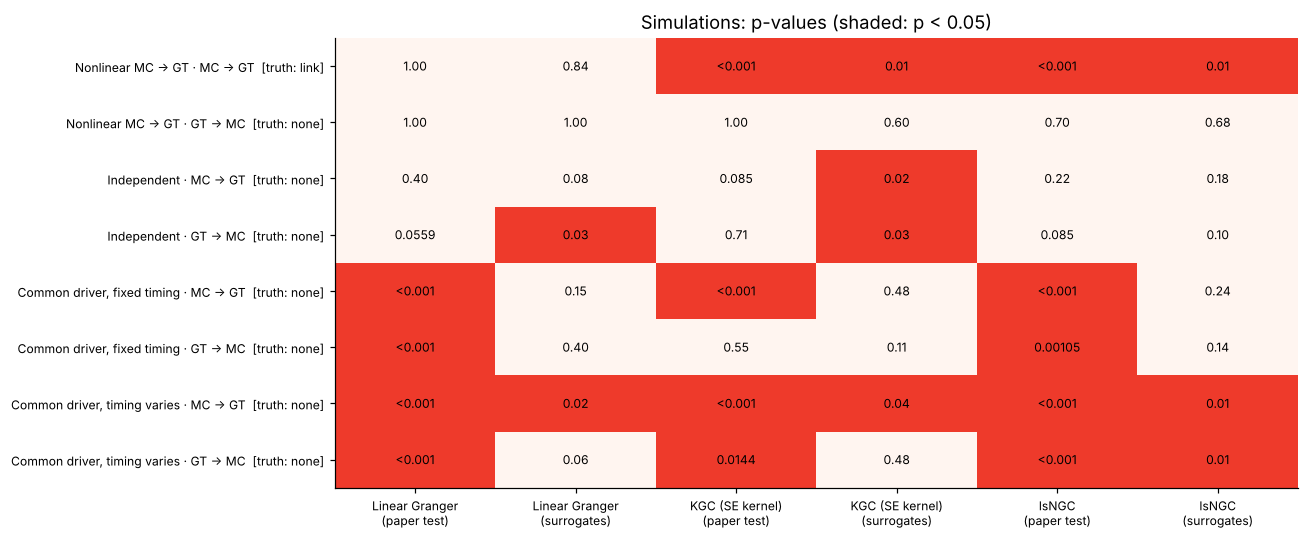

In [3]:
def pvalue_grid(ax, P, rows, cols, title):
    ax.imshow(np.where(np.isnan(P), 1, P) < ALPHA, cmap="Reds", vmin=0, vmax=1.6, aspect="auto")
    for i in range(P.shape[0]):
        for j in range(P.shape[1]):
            ax.text(j, i, fmt_p(P[i, j]), ha="center", va="center", fontsize=8)
    ax.set_xticks(range(len(cols)), cols, fontsize=8)
    ax.set_yticks(range(len(rows)), rows, fontsize=8)
    ax.set_title(title)


fig, ax = plt.subplots(figsize=(12, 5))
pvalue_grid(ax, sim[[c for c, _ in TESTS]].to_numpy(float),
            [f"{r.scenario} · {r.direction}  [truth: {'link' if r.truth else 'none'}]" for r in sim.itertuples()],
            [t for _, t in TESTS], "Simulations: p-values (shaded: p < 0.05)")
fig.tight_layout()
fig.savefig(FIG_DIR / "kg01_simulation_single.png", dpi=200, bbox_inches="tight")

### 2.2 Rejection rates over 100 simulated datasets per scenario

Each scenario is simulated 100 times (different random seeds) and each test is run on
every dataset (39 surrogates per test). The rejection rate is the share of datasets in
which the test declares a link at the 5% level; 95% Wilson intervals give its precision.

In [4]:
rate_jobs = [(sc, e, c, lab, seed) for sc in S.SCENARIOS for e, c, lab in DIRS for seed in RATE_SEEDS]
CHUNK = 40   # jobs per cached chunk: an interrupted run resumes from the last saved chunk
rates_raw = pd.concat([
    cached(f"sim_rates_{RATE_SEEDS[-1] + 1}_{i}", lambda chunk=rate_jobs[i:i + CHUNK]: pd.DataFrame(
        Parallel(n_jobs=N_JOBS)(delayed(sim_one)(sc, e, c, lab, N_SURR_RATE, seed=seed)
                                for sc, e, c, lab, seed in chunk)))
    for i in range(0, len(rate_jobs), CHUNK)], ignore_index=True)

def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n."""
    p = k / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centre - half, centre + half


rate_names = {c: t.replace("\n", " ") for c, t in TESTS}
grp = rates_raw.assign(**{c: rates_raw[c] < ALPHA for c in rate_names}).groupby(
    ["scenario", "direction", "truth"], sort=False)
rate_table = grp[list(rate_names)].mean().rename(columns=rate_names)
n_sets = grp.size()
rate_lo = rate_table.apply(lambda col: wilson(col * n_sets, n_sets)[0])
rate_hi = rate_table.apply(lambda col: wilson(col * n_sets, n_sets)[1])
pd.concat({"rate": rate_table, "ci_low": rate_lo, "ci_high": rate_hi}, axis=1).to_csv(
    TAB_DIR / "kernel_granger_simulation_rates.csv")
print(f"{int(n_sets.iloc[0])} datasets per scenario and direction")
(rate_table.round(2).astype(str) + " [" + rate_lo.round(2).astype(str) + ", "
 + rate_hi.round(2).astype(str) + "]")

[sim_rates_100_0] loaded from cache
[sim_rates_100_40] loaded from cache
[sim_rates_100_80] loaded from cache
[sim_rates_100_120] loaded from cache
[sim_rates_100_160] loaded from cache
[sim_rates_100_200] loaded from cache
[sim_rates_100_240] loaded from cache
[sim_rates_100_280] loaded from cache
[sim_rates_100_320] loaded from cache
[sim_rates_100_360] loaded from cache
[sim_rates_100_400] loaded from cache
[sim_rates_100_440] loaded from cache
[sim_rates_100_480] loaded from cache
[sim_rates_100_520] loaded from cache
[sim_rates_100_560] loaded from cache
[sim_rates_100_600] loaded from cache
[sim_rates_100_640] loaded from cache
[sim_rates_100_680] loaded from cache
[sim_rates_100_720] loaded from cache
[sim_rates_100_760] loaded from cache
100 datasets per scenario and direction


Linear Granger (paper test) Linear Granger (surrogates) KGC (SE kernel) (paper test) KGC (SE kernel) (surrogates) lsNGC (paper test) lsNGC (surrogates)
scenario                     direction truth                                                                                                                                                        
Nonlinear MC → GT            MC → GT   True            0.29 [0.21, 0.39]           0.27 [0.19, 0.36]              1.0 [0.96, 1.0]              1.0 [0.96, 1.0]    1.0 [0.96, 1.0]    1.0 [0.96, 1.0]
                             GT → MC   False           0.06 [0.03, 0.12]            0.01 [0.0, 0.05]            0.06 [0.03, 0.12]            0.07 [0.03, 0.14]  0.05 [0.02, 0.11]   0.01 [0.0, 0.05]
Independent                  MC → GT   False           0.05 [0.02, 0.11]            0.04 [0.02, 0.1]            0.07 [0.03, 0.14]            0.06 [0.03, 0.12]   0.04 [0.02, 0.1]  0.02 [0.01, 0.07]
                             GT → MC   False           0.05 [0.02, 0.11]             0.0 [0.0, 0.04]            0.07 [0.03, 0.14]            0.05 [0.02, 0.11]   0.04 [0.02, 0.1]   0.01 [0.0, 0.05]
Common driver, fixed timing  MC → GT   False             1.0 [0.96, 1.0]           0.06 [0.03, 0.12]             0.99 [0.95, 1.0]            0.07 [0.03, 0.14]    1.0 [0.96, 1.0]  0.05 [0.02, 0.11]
                             GT → MC   False            0.9 [0.83, 0.94]           0.06 [0.03, 0.12]             0.39 [0.3, 0.49]             0.04 [0.02, 0.1]  0.66 [0.56, 0.75]   0.04 [0.02, 0.1]
Common driver, timing varies MC → GT   False             1.0 [0.96, 1.0]           0.94 [0.88, 0.97]            0.98 [0.93, 0.99]            0.77 [0.68, 0.84]    1.0 [0.96, 1.0]  0.92 [0.85, 0.96]
                             GT → MC   False           0.92 [0.85, 0.96]           0.48 [0.38, 0.58]            0.48 [0.38, 0.58]            0.32 [0.24, 0.42]  0.68 [0.58, 0.76]  0.33 [0.25, 0.43]

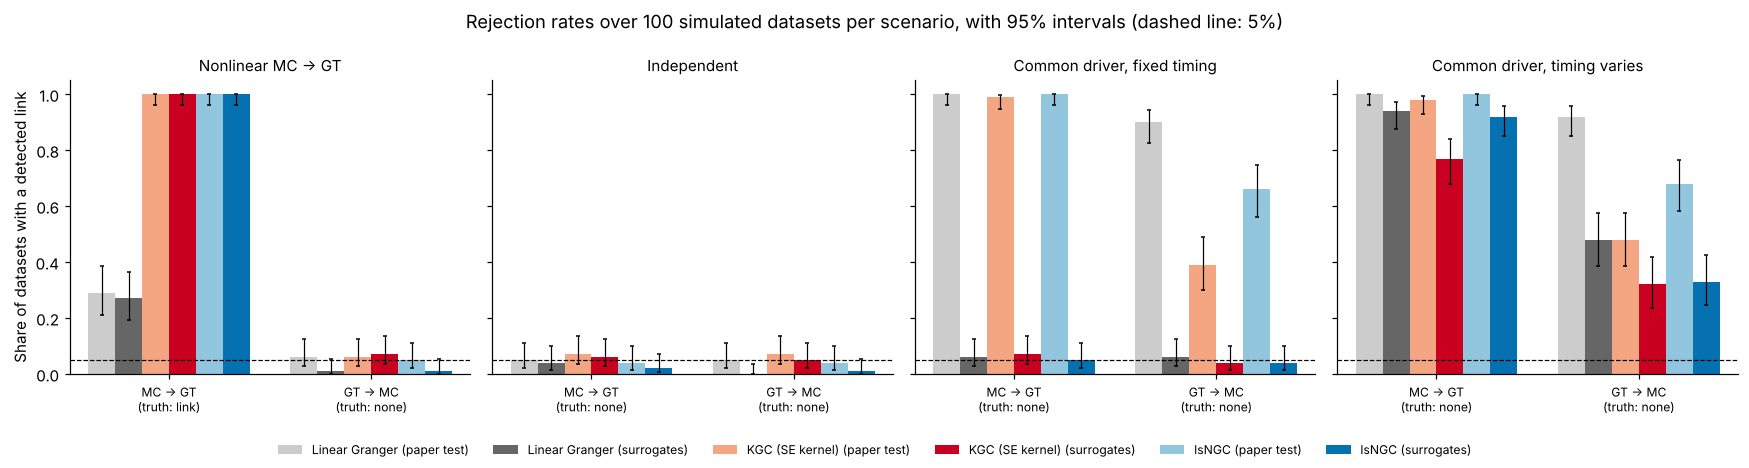

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
colors = ["#cccccc", "#666666", "#f4a582", "#ca0020", "#92c5de", "#0571b0"]
names = list(rate_names.values())
for ax, sc in zip(axes, S.SCENARIOS):
    sub = rate_table.loc[sc]
    x = np.arange(len(sub))
    w = 0.8 / len(names)
    for j, (nm, col) in enumerate(zip(names, colors)):
        lo, hi = rate_lo.loc[sc][nm], rate_hi.loc[sc][nm]
        ax.bar(x + (j - len(names) / 2 + 0.5) * w, sub[nm], w, color=col, label=nm,
               yerr=[np.clip(sub[nm] - lo, 0, None), np.clip(hi - sub[nm], 0, None)], error_kw={"lw": 0.8, "capsize": 1.5, "ecolor": "black"})
    ax.axhline(ALPHA, color="black", lw=0.8, ls="--")
    ax.set_xticks(x, [f"{d}\n(truth: {'link' if t else 'none'})" for d, t in sub.index], fontsize=8)
    ax.set_title(sc, fontsize=10)
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("Share of datasets with a detected link")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=6, fontsize=8, frameon=False)
fig.suptitle(f"Rejection rates over {len(RATE_SEEDS)} simulated datasets per scenario, with 95% intervals (dashed line: 5%)")
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIG_DIR / "kg02_simulation_rates.png", dpi=200, bbox_inches="tight")

**What the simulations show** (100 datasets per scenario; counts out of 100):

* **Power.** KGC (SE kernel) and lsNGC detect the quadratic MC → GT link in all 100
  datasets, with or without surrogates. Linear Granger causality detects it in only 27–29:
  the link exists but has no linear correlation.
* **No link.** Every test declares a link in 0–7 datasets out of 100. This is consistent
  with a 5% level: with 100 datasets, a true rate of 5% is observed between about 2 and 11.
* **Common driver with fixed timing.** The paper tests declare a link in 39–100 datasets,
  although there is none. With season-swap surrogates this drops to 4–7.
* **Common driver whose timing changes every year.** All tests, including the surrogate
  tests, still declare links (32–94 datasets with surrogates). No test in this notebook can
  separate this situation from a real link.

For real data, the paper tests therefore cannot be trusted on their own, the surrogate
tests remove the effect of a fixed campaign calendar, and any link they find could still
come from events whose date varies from year to year.

## 3. Real data: lag order

The lag order $m$ is chosen for each effect series from its **own** past only (without the
cause), by leave-one-season-out cross-validation of a kernel ridge model, so that the
choice of $m$ cannot favour finding causality. All orders are compared on the same days
(from day 7 of each window).

In [6]:
data = {c: load_daily(c) for c in CODES}

lag_cv = cached("lag_cv", lambda: {
    (c, lab, cond): K.select_lag(data[c], e, a, LAGS, conditional=cond)
    for c in CODES for e, a, lab in DIRS for cond in (False, True)})

best_m = {k: int(v.idxmin()) for k, v in lag_cv.items()}
pd.DataFrame({"unconditional": {f"{LABEL[c]} · {lab}": best_m[c, lab, False] for c in CODES for _, _, lab in DIRS},
              "calendar-conditioned": {f"{LABEL[c]} · {lab}": best_m[c, lab, True] for c in CODES for _, _, lab in DIRS}})

[lag_cv] loaded from cache


,unconditional,calendar-conditioned
Dry January · MC → GT,2,3
Dry January · GT → MC,1,1
Mars Bleu · MC → GT,7,3
Mars Bleu · GT → MC,7,7
Movember · MC → GT,5,2
Movember · GT → MC,7,5
Octobre Rose · MC → GT,2,2
Octobre Rose · GT → MC,5,3


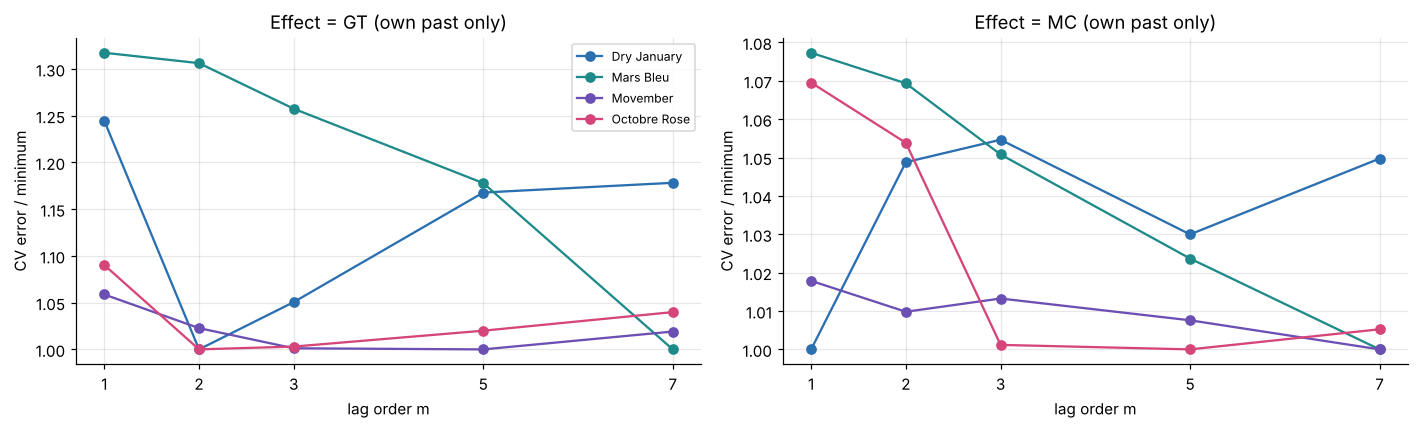

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (e, a, lab) in zip(axes, DIRS):
    for c in CODES:
        s = lag_cv[c, lab, False]
        ax.plot(s.index, s / s.min(), marker="o", color=CAMPAIGNS[c].color, label=LABEL[c])
    ax.set(title=f"Effect = {'GT' if e == 'gt' else 'MC'} (own past only)", xlabel="lag order m",
           ylabel="CV error / minimum", xticks=LAGS)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "kg03_lag_selection.png", dpi=200, bbox_inches="tight")

## 4. Real data: tests

For each campaign, direction and variant, KGC (linear and SE kernels) and lsNGC are run
with their parametric tests and with 199 season-swap surrogates.

In [8]:
main_jobs = [(c, e, a, lab, cond) for cond in (False, True) for c in CODES for e, a, lab in DIRS]


def real_one(c, e, a, lab, cond, seed):
    r = K.run_tests(data[c], e, a, m=best_m[c, lab, cond], conditional=cond, start=START,
                    n_surrogates=N_SURR, seed=seed)
    return {"campaign": LABEL[c], "direction": lab,
            "variant": "calendar-conditioned" if cond else "unconditional", **r}


main_raw = cached("main", lambda: Parallel(n_jobs=N_JOBS)(
    delayed(real_one)(*j, seed=1000 + i) for i, j in enumerate(main_jobs)))
main = pd.DataFrame([strip(r) for r in main_raw])

for k in METHODS:
    adj_param = K.benjamini_hochberg if k == "lsngc" else K.holm
    main[f"{k}_p_param_adj"] = main.groupby("variant")[f"{k}_p_param"].transform(lambda p: adj_param(p))
    main[f"{k}_p_surr_adj"] = main.groupby("variant")[f"{k}_p_surr"].transform(lambda p: K.holm(p))
main.to_csv(TAB_DIR / "kernel_granger_main.csv", index=False)

show = ["campaign", "direction", "variant", "m", "n",
        "kgc_se_delta", "kgc_se_null_mean", "kgc_se_n_f", "kgc_se_p_param_adj", "kgc_se_p_surr_adj",
        "lsngc_delta", "lsngc_null_mean", "lsngc_p_param_adj", "lsngc_p_surr_adj",
        "kgc_lin_p_param_adj", "kgc_lin_p_surr_adj"]
main[show].round(4)

[main] loaded from cache


,campaign,direction,variant,m,n,kgc_se_delta,kgc_se_null_mean,kgc_se_n_f,kgc_se_p_param_adj,kgc_se_p_surr_adj,lsngc_delta,lsngc_null_mean,lsngc_p_param_adj,lsngc_p_surr_adj,kgc_lin_p_param_adj,kgc_lin_p_surr_adj
0,Dry January,MC → GT,unconditional,2,396,0.3015,0.2141,1,0.1309,0.70,0.0499,0.0229,0.0014,0.400,0.0017,0.260
1,Dry January,GT → MC,unconditional,1,396,0.2239,0.1598,3,0.0000,0.70,0.1193,0.0693,0.0000,0.390,0.0000,0.090
2,Mars Bleu,MC → GT,unconditional,7,891,0.1977,0.1970,0,0.4682,1.00,0.0041,0.0115,0.5362,1.000,1.0000,1.000
3,Mars Bleu,GT → MC,unconditional,7,891,0.2158,0.2086,0,0.4624,1.00,0.0101,0.0057,0.0891,0.520,0.0178,0.040
4,Movember,MC → GT,unconditional,5,935,0.1918,0.1487,1,0.1089,0.12,0.0265,0.0060,0.0001,0.040,0.2681,0.070
5,Movember,GT → MC,unconditional,7,935,0.1721,0.1925,1,0.0067,1.00,0.0341,0.0257,0.0000,0.385,0.0000,0.090
6,Octobre Rose,MC → GT,unconditional,2,924,0.1312,0.1523,3,0.0000,1.00,0.0032,0.0157,0.5733,1.000,1.0000,1.000
7,Octobre Rose,GT → MC,unconditional,5,924,0.3123,0.3249,4,0.0010,1.00,0.0364,0.0522,0.0000,1.000,0.0001,1.000
8,Dry January,MC → GT,calendar-conditioned,3,396,0.3346,0.4341,1,0.0376,1.00,0.0299,0.0219,0.0497,1.000,0.0513,0.480
9,Dry January,GT → MC,calendar-conditioned,1,396,0.1628,0.1664,1,0.1020,1.00,0.0221,0.0282,0.1118,1.000,0.0000,0.040


### 4.1 Summary of the evidence

Each cell is an adjusted p-value (shaded when < 0.05). The paper tests do not account for
the shared campaign calendar; the surrogate tests do (for a fixed calendar).

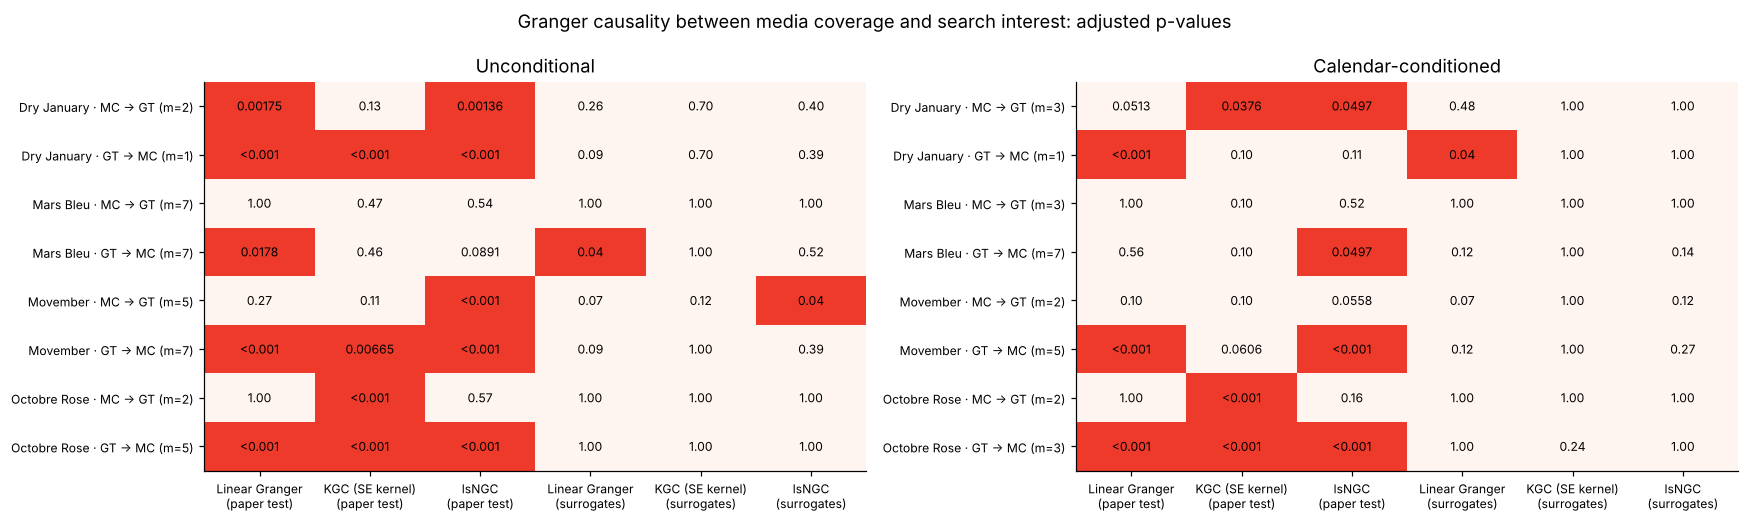

In [9]:
SUMMARY = ([(f"{k}_p_param_adj", f"{v}\n(paper test)") for k, v in METHODS.items()]
           + [(f"{k}_p_surr_adj", f"{v}\n(surrogates)") for k, v in METHODS.items()])
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, var in zip(axes, ["unconditional", "calendar-conditioned"]):
    sub = main[main["variant"] == var].reset_index(drop=True)
    pvalue_grid(ax, sub[[c for c, _ in SUMMARY]].to_numpy(float),
                [f"{r.campaign} · {r.direction} (m={r.m})" for r in sub.itertuples()],
                [t for _, t in SUMMARY], var.capitalize())
fig.suptitle("Granger causality between media coverage and search interest: adjusted p-values")
fig.tight_layout()
fig.savefig(FIG_DIR / "kg04_main_results.png", dpi=200, bbox_inches="tight")

### 4.2 Observed statistic against its surrogate distribution

Red line: share of the restricted model's unexplained variance captured by the real cause
($\delta$). Histogram: the same statistic for 199 surrogate causes taken from other seasons.

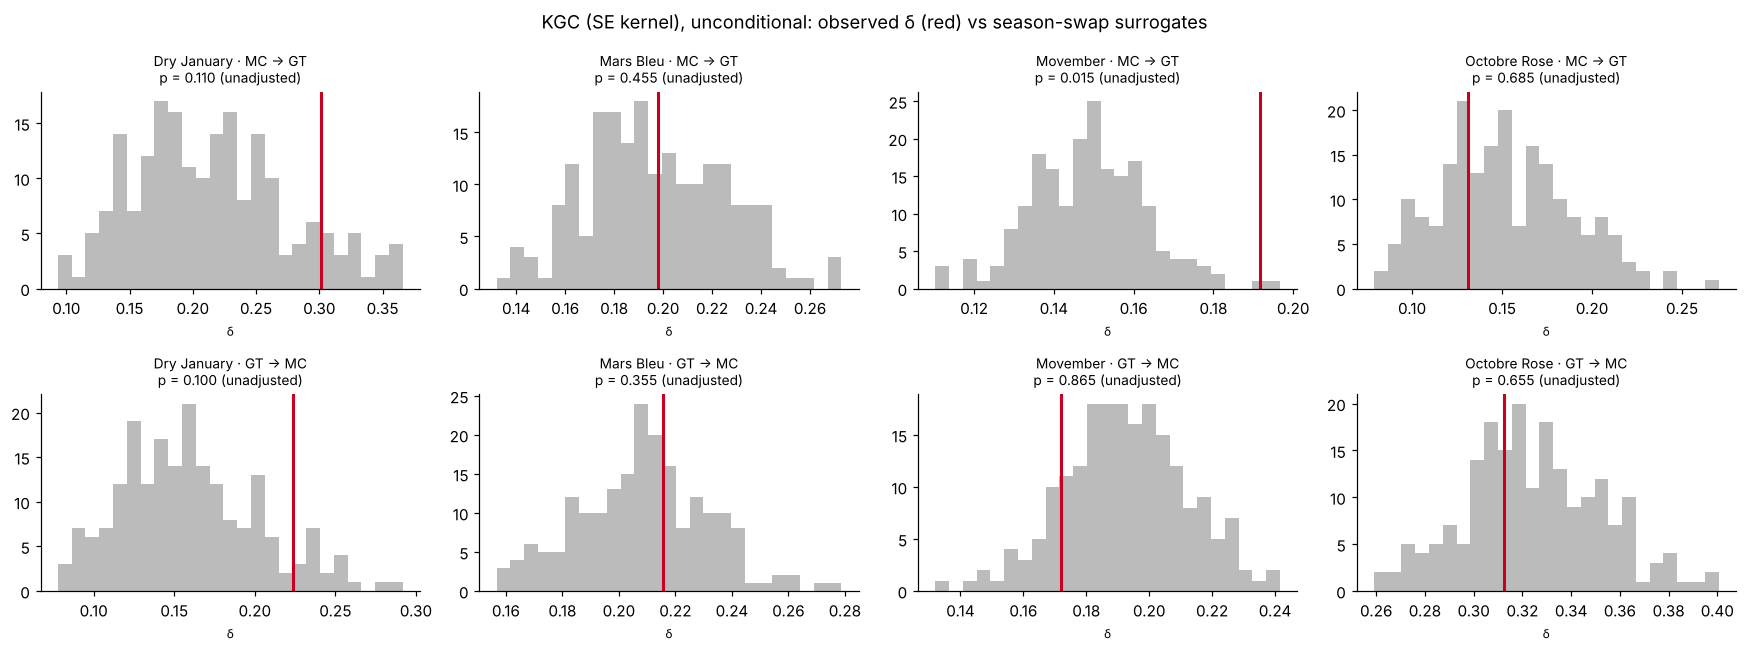

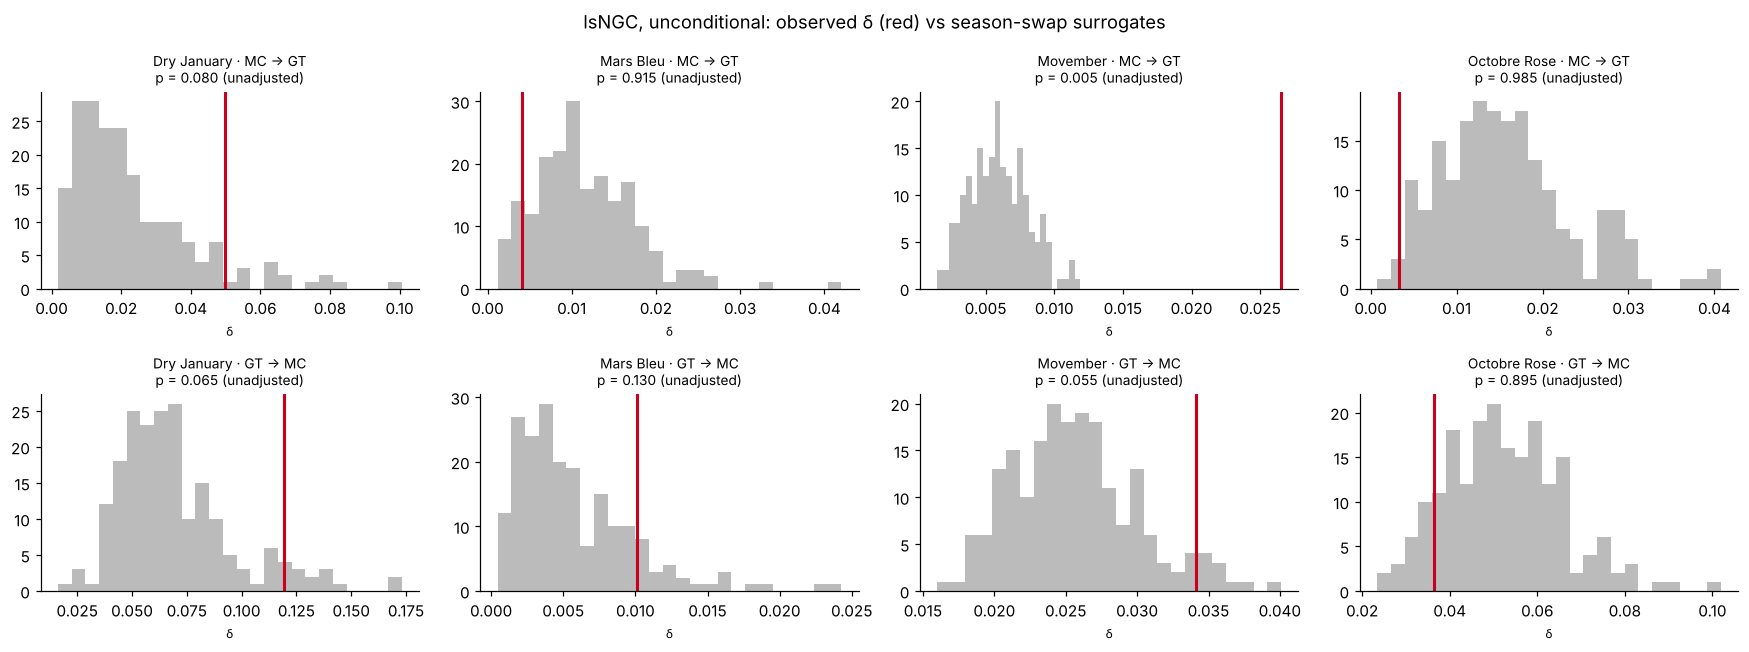

In [10]:
for key in ("kgc_se", "lsngc"):
    fig, axes = plt.subplots(2, 4, figsize=(16, 6))
    for ax, r in zip(axes.T.flat, [r for r in main_raw if not r["conditional"]]):
        obs, null = r["nulls"][key]
        ax.hist(null, bins=25, color="#bbbbbb")
        ax.axvline(obs, color="#ca0020", lw=2)
        ax.set_title(f"{r['campaign']} · {r['direction']}\np = {K.surrogate_pvalue(obs, null):.3f} (unadjusted)",
                     fontsize=9)
        ax.set_xlabel("δ", fontsize=8)
    fig.suptitle(f"{METHODS[key]}, unconditional: observed δ (red) vs season-swap surrogates")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"kg05_null_{key}.png", dpi=200, bbox_inches="tight")

### 4.3 Confidence intervals of the statistic (delete-one-season jackknife)

The surrogate test says whether $\delta$ is larger than chance; the jackknife says how
precisely $\delta$ is estimated. Each season is removed in turn and $\delta$ is recomputed with
the same lag order (and, for lsNGC, the same k-means seed as the main test); the 95% interval
is $\hat\delta \pm 1.96\,SE_{\text{jack}}$. The chance level of $\delta$ is its mean over surrogates.

A season bootstrap (resampling seasons with replacement) is not used: drawing the same season
twice inflates in-sample statistics such as $\delta$, and in a first run its intervals lay
above the observed value for most KGC tests.

In [11]:
jk_jobs = [(c, e, a, lab, best_m[c, lab, False], key, 1000 + i)
           for key in ("kgc_se", "lsngc")
           for i, (c, e, a, lab, cond) in enumerate(main_jobs) if not cond]


def jk_one(c, e, a, lab, m, key, seed):
    reps = K.jackknife_delta(data[c], e, a, m, key, seed=seed, start=START)
    return {"campaign": LABEL[c], "direction": lab, "method": METHODS[key], "m": m, "replicates": reps}


jk = cached("jackknife_delta", lambda: Parallel(n_jobs=N_JOBS)(delayed(jk_one)(*j) for j in jk_jobs))
unc = main[main["variant"] == "unconditional"]
rows = []
for r in jk:
    key = {v: k for k, v in METHODS.items()}[r["method"]]
    row = unc[(unc["campaign"] == r["campaign"]) & (unc["direction"] == r["direction"])].iloc[0]
    se, lo, hi = K.jackknife_ci(row[f"{key}_delta"], r["replicates"])
    rows.append({"method": r["method"], "campaign": r["campaign"], "direction": r["direction"], "m": r["m"],
                 "delta": row[f"{key}_delta"], "se_jack": se, "ci_low": lo, "ci_high": hi,
                 "surrogate_mean": row[f"{key}_null_mean"], "p_surr_holm": row[f"{key}_p_surr_adj"]})
jk_table = pd.DataFrame(rows)
jk_table.to_csv(TAB_DIR / "kernel_granger_jackknife_delta.csv", index=False)
jk_table.round(4)

[jackknife_delta] loaded from cache


,method,campaign,direction,m,delta,se_jack,ci_low,ci_high,surrogate_mean,p_surr_holm
0,KGC (SE kernel),Dry January,MC → GT,2,0.3015,0.1481,0.0113,0.5917,0.2141,0.700
1,KGC (SE kernel),Dry January,GT → MC,1,0.2239,0.0644,0.0976,0.3502,0.1598,0.700
2,KGC (SE kernel),Mars Bleu,MC → GT,7,0.1977,0.0490,0.1017,0.2938,0.1970,1.000
3,KGC (SE kernel),Mars Bleu,GT → MC,7,0.2158,0.0511,0.1155,0.3160,0.2086,1.000
4,KGC (SE kernel),Movember,MC → GT,5,0.1918,0.0391,0.1151,0.2685,0.1487,0.120
5,KGC (SE kernel),Movember,GT → MC,7,0.1721,0.0409,0.0919,0.2522,0.1925,1.000
6,KGC (SE kernel),Octobre Rose,MC → GT,2,0.1312,0.0379,0.0570,0.2055,0.1523,1.000
7,KGC (SE kernel),Octobre Rose,GT → MC,5,0.3123,0.0496,0.2150,0.4096,0.3249,1.000
8,lsNGC,Dry January,MC → GT,2,0.0499,0.0543,-0.0565,0.1563,0.0229,0.400
9,lsNGC,Dry January,GT → MC,1,0.1193,0.0753,-0.0282,0.2668,0.0693,0.390


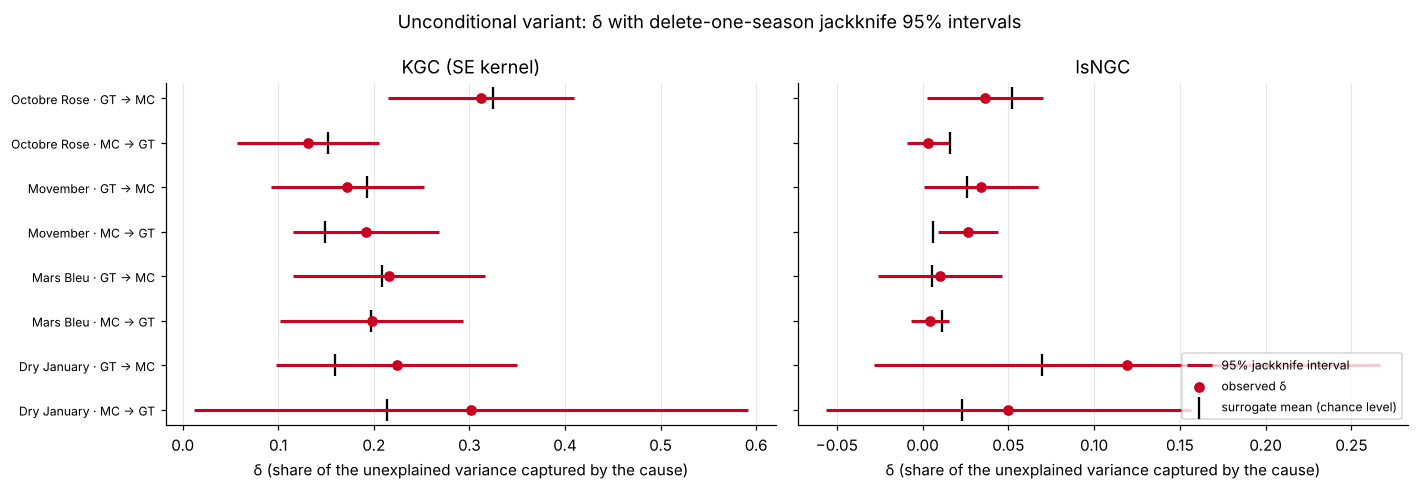

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, key in zip(axes, ("kgc_se", "lsngc")):
    sub = jk_table[jk_table["method"] == METHODS[key]].reset_index(drop=True)
    y = np.arange(len(sub))
    ax.hlines(y, sub["ci_low"], sub["ci_high"], color="#ca0020", lw=2, label="95% jackknife interval")
    ax.scatter(sub["delta"], y, color="#ca0020", zorder=3, label="observed δ")
    ax.scatter(sub["surrogate_mean"], y, marker="|", s=200, color="black", label="surrogate mean (chance level)")
    ax.set_yticks(y, [f"{r.campaign} · {r.direction}" for r in sub.itertuples()], fontsize=8)
    ax.set_title(METHODS[key])
    ax.set_xlabel("δ (share of the unexplained variance captured by the cause)")
    ax.grid(axis="x", alpha=0.3)
axes[1].legend(fontsize=8, loc="lower right")
fig.suptitle("Unconditional variant: δ with delete-one-season jackknife 95% intervals")
fig.tight_layout()
fig.savefig(FIG_DIR / "kg07_jackknife_delta.png", dpi=200, bbox_inches="tight")

### 4.4 Robustness of lsNGC to the k-means initialisation

lsNGC places its radial basis functions with k-means, whose result depends on a random
initialisation, so $\delta$ varies slightly with the seed. The surrogate test stays valid for
any seed (the real and surrogate causes use the same one), but a conclusion should not depend
on it. The unconditional tests are repeated with 10 seeds (199 surrogates each), with Holm
correction across the 8 tests for each seed.

In [13]:
seed_jobs = [(c, e, a, lab, best_m[c, lab, False], s) for s in range(N_SEEDS) for c in CODES for e, a, lab in DIRS]


def seed_one(c, e, a, lab, m, s):
    r = K.run_tests(data[c], e, a, m=m, start=START, n_surrogates=N_SURR, seed=2000 + s, methods=("lsngc",))
    return {"seed": s, "campaign": LABEL[c], "direction": lab, "delta": r["lsngc_delta"],
            "p_surr": r["lsngc_p_surr"]}


seeds = cached("lsngc_seeds", lambda: pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(seed_one)(*j) for j in seed_jobs)))
seeds["p_holm"] = seeds.groupby("seed")["p_surr"].transform(lambda p: K.holm(p))
seed_table = seeds.groupby(["campaign", "direction"], sort=False).agg(
    delta_min=("delta", "min"), delta_max=("delta", "max"),
    p_surr_min=("p_surr", "min"), p_surr_max=("p_surr", "max"),
    seeds_significant_after_holm=("p_holm", lambda p: f"{(p < ALPHA).sum()}/{len(p)}"))
seed_table.to_csv(TAB_DIR / "kernel_granger_lsngc_seeds.csv")
seed_table.round(4)

[lsngc_seeds] loaded from cache


delta_min  delta_max  p_surr_min  p_surr_max seeds_significant_after_holm
campaign     direction                                                                           
Dry January  MC → GT       0.0382     0.0528       0.055       0.175                         0/10
             GT → MC       0.1192     0.1194       0.035       0.090                         0/10
Mars Bleu    MC → GT       0.0032     0.0067       0.855       0.985                         0/10
             GT → MC       0.0122     0.0241       0.005       0.060                         5/10
Movember     MC → GT       0.0236     0.0279       0.005       0.005                        10/10
             GT → MC       0.0312     0.0341       0.010       0.035                         0/10
Octobre Rose MC → GT       0.0015     0.0034       0.960       1.000                         0/10
             GT → MC       0.0331     0.0392       0.865       0.945                         0/10

## 5. Sensitivity to the lag order

Both nonlinear methods with surrogates for every lag order, unconditional variant
(39 surrogates, unadjusted p-values, resolution 0.025). A robust link should not depend
on one particular $m$.

[lag_sensitivity] loaded from cache


kgc_se                              lsngc                            
m                           1      2      3      5      7      1      2      3      5      7
campaign     direction                                                                      
Dry January  GT → MC    0.050  0.050  0.125  0.375  0.350  0.100  0.150  0.200  0.275  0.100
             MC → GT    0.025  0.175  0.575  0.875  0.950  0.100  0.100  0.225  0.600  0.425
Mars Bleu    GT → MC    0.325  0.525  0.050  0.450  0.325  0.075  0.450  0.150  0.675  0.025
             MC → GT    0.825  0.850  0.800  0.475  0.425  0.750  1.000  0.900  0.875  0.825
Movember     GT → MC    0.050  0.075  0.175  0.375  0.850  0.025  0.025  0.050  0.025  0.050
             MC → GT    0.075  0.300  0.050  0.025  0.025  0.025  0.025  0.025  0.025  0.025
Octobre Rose GT → MC    0.500  0.050  0.125  0.750  0.950  0.775  0.925  0.625  0.900  0.775
             MC → GT    0.750  0.750  0.750  0.650  0.700  0.175  1.000  1.000  0.950  0.575

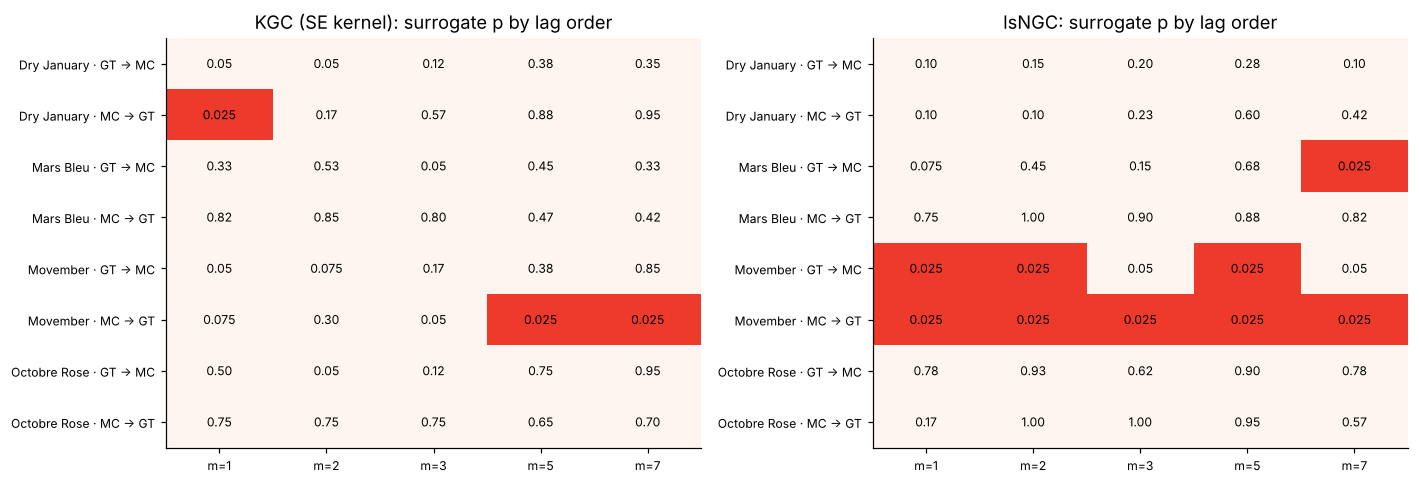

In [14]:
sens_jobs = [(c, e, a, lab, m) for c in CODES for e, a, lab in DIRS for m in LAGS]


def sens_one(c, e, a, lab, m):
    r = K.run_tests(data[c], e, a, m=m, start=START, n_surrogates=N_SURR_RATE, seed=m,
                    methods=("kgc_se", "lsngc"))
    return {"campaign": LABEL[c], "direction": lab, "m": m,
            "kgc_se": r["kgc_se_p_surr"], "lsngc": r["lsngc_p_surr"]}


sens = cached("lag_sensitivity", lambda: pd.DataFrame(Parallel(n_jobs=N_JOBS)(
    delayed(sens_one)(*j) for j in sens_jobs)))
sens.to_csv(TAB_DIR / "kernel_granger_lag_sensitivity.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, key in zip(axes, ("kgc_se", "lsngc")):
    sp = sens.pivot_table(index=["campaign", "direction"], columns="m", values=key)
    pvalue_grid(ax, sp.to_numpy(float), [f"{a} · {b}" for a, b in sp.index],
                [f"m={m}" for m in sp.columns], f"{METHODS[key]}: surrogate p by lag order")
fig.tight_layout()
fig.savefig(FIG_DIR / "kg06_lag_sensitivity.png", dpi=200, bbox_inches="tight")
sens.pivot_table(index=["campaign", "direction"], columns="m", values=["kgc_se", "lsngc"]).round(3)

## 6. The weekly cycle: a second shared calendar

Searches and newspapers both follow a weekly cycle (fewer articles and fewer searches at
weekends; notebook 06, Section 1). A season-swap surrogate pairs each season with another
year **at the same calendar dates**, and a given date falls on a different day of the week
from one year to the next. The swap therefore keeps the campaign profile aligned but
breaks the weekly cycle, so in principle the real pair could beat its surrogates only
because its two series share the same weekdays. Whether this matters is checked in
simulation (6.1) and on the real data (6.2–6.5). The simulation does **not** show inflated
rejection rates; the real data show that the weekly cycle still changes the linear and KGC
results, and we have no explanation for the difference.

Two remedies are compared with the procedure used so far:

| Procedure | Surrogate cause |
|---|---|
| **dates aligned** (Sections 2–5) | another season, same calendar dates |
| **weekdays aligned** | another season, shifted by at most ±3 days so that every day receives a day with the same weekday |
| **weekly cycle removed** | the day-of-week effect of each series is estimated and subtracted first (`transfer.remove_weekday`), then dates aligned |

The second keeps the weekly cycle aligned at the cost of misaligning calendar dates by up
to three days; the third keeps dates aligned but removes only an additive, constant
weekly effect.

### 6.1 Simulation

The "common driver, fixed timing" system of Section 2 (no direct link), to which a weekly
cycle shared by both series is added, of the size seen in the data (5–10% of the variance
not explained by the campaign pulse). 100 datasets, 39 surrogates, $m=3$.

In [15]:
PROCS = {"date": "dates aligned", "weekday": "weekdays aligned", "adjusted": "weekly cycle removed"}


def wk_sim_one(seed, proc):
    df = S.common_driver(seed, weekday=0.5)
    if proc == "adjusted":
        df = T.remove_weekday(df)
    rows = []
    for e, c, lab in DIRS:
        r = K.run_tests(df, e, c, m=3, start=START, n_surrogates=N_SURR_RATE, seed=seed + 100,
                        align_weekday=(proc == "weekday"))
        rows.append({"procedure": PROCS[proc], "direction": lab, "seed": seed,
                     **{METHODS[k]: r[f"{k}_p_surr"] for k in METHODS}})
    return rows


wk_jobs = [(seed, proc) for proc in PROCS for seed in RATE_SEEDS]
wk_sim = pd.concat([
    cached(f"weekly_sim_{RATE_SEEDS[-1] + 1}_{i}", lambda chunk=wk_jobs[i:i + CHUNK]: pd.DataFrame(
        [r for rows in Parallel(n_jobs=N_JOBS)(delayed(wk_sim_one)(*j) for j in chunk) for r in rows]))
    for i in range(0, len(wk_jobs), CHUNK)], ignore_index=True)

wk_rates = (wk_sim.assign(**{v: wk_sim[v] < ALPHA for v in METHODS.values()})
            .groupby(["procedure", "direction"], sort=False)[list(METHODS.values())].mean())
wk_rates.to_csv(TAB_DIR / "kernel_granger_weekly_cycle_simulation.csv")
print("Share of 100 datasets with no direct link in which the surrogate test declares one "
      f"(a true rate of 5% is observed between {wilson(5, 100)[0]:.0%} and {wilson(5, 100)[1]:.0%}):")
wk_rates.round(2)

[weekly_sim_100_0] loaded from cache
[weekly_sim_100_40] loaded from cache
[weekly_sim_100_80] loaded from cache
[weekly_sim_100_120] loaded from cache
[weekly_sim_100_160] loaded from cache
[weekly_sim_100_200] loaded from cache
[weekly_sim_100_240] loaded from cache
[weekly_sim_100_280] loaded from cache
Share of 100 datasets with no direct link in which the surrogate test declares one (a true rate of 5% is observed between 2% and 11%):


Linear Granger  KGC (SE kernel)  lsNGC
procedure            direction                                        
dates aligned        MC → GT              0.02             0.02   0.00
                     GT → MC              0.01             0.02   0.00
weekdays aligned     MC → GT              0.06             0.04   0.07
                     GT → MC              0.03             0.04   0.00
weekly cycle removed MC → GT              0.05             0.06   0.05
                     GT → MC              0.06             0.04   0.03

### 6.2 Real data

The eight unconditional tests of Section 4 are repeated under the three procedures, with
the same lag orders and 999 surrogates (smallest attainable p-value 0.001, so that a Holm
correction over eight tests can reach 0.008).

[weekly_real_999_0] loaded from cache
[weekly_real_999_4] loaded from cache
[weekly_real_999_8] loaded from cache
[weekly_real_999_12] loaded from cache
[weekly_real_999_16] loaded from cache
[weekly_real_999_20] loaded from cache


kgc_lin_p_surr                                       kgc_se_p_surr                                        lsngc_p_surr                                      
procedure               dates aligned weekdays aligned weekly cycle removed dates aligned weekdays aligned weekly cycle removed dates aligned weekdays aligned weekly cycle removed
campaign     direction                                                                                                                                                             
Dry January  GT → MC            0.005            0.001                0.006         0.062            0.002                0.047         0.053            0.006                0.059
             MC → GT            0.088            0.027                0.074         0.121            0.005                0.114         0.092            0.012                0.050
Mars Bleu    GT → MC            0.001            0.141                0.107         0.346            0.629                0.454         0.124            0.396                0.235
             MC → GT            0.916            0.884                0.686         0.471            0.509                0.444         0.928            0.740                0.514
Movember     GT → MC            0.010            0.298                0.011         0.863            0.744                0.687         0.028            0.247                0.096
             MC → GT            0.003            0.040                0.084         0.005            0.044                0.040         0.001            0.001                0.001
Octobre Rose GT → MC            0.795            0.818                0.927         0.667            0.737                0.995         0.897            0.895                0.805
             MC → GT            0.978            0.994                0.986         0.701            0.799                0.663         0.986            0.952                0.885

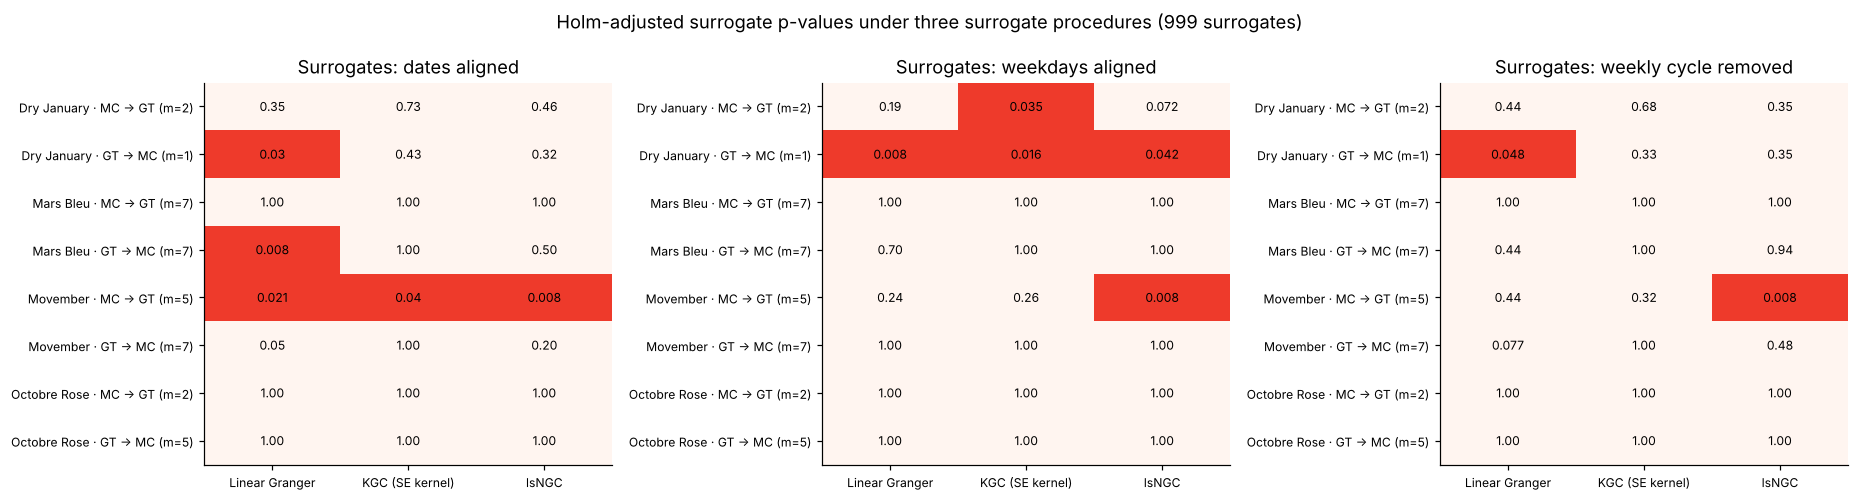

In [16]:
wk_real_jobs = [(c, e, a, lab, proc, 1000 + i) for proc in PROCS
                for i, (c, e, a, lab, cond) in enumerate(main_jobs) if not cond]


def wk_real_one(c, e, a, lab, proc, seed):
    df = T.remove_weekday(data[c]) if proc == "adjusted" else data[c]
    r = K.run_tests(df, e, a, m=best_m[c, lab, False], start=START, n_surrogates=N_SURR_BIG,
                    seed=seed, align_weekday=(proc == "weekday"))
    return {"campaign": LABEL[c], "direction": lab, "procedure": PROCS[proc], **strip(r)}


wk_real = pd.concat([
    cached(f"weekly_real_{N_SURR_BIG}_{i}", lambda chunk=wk_real_jobs[i:i + 4]: pd.DataFrame(
        Parallel(n_jobs=N_JOBS)(delayed(wk_real_one)(*j) for j in chunk)))
    for i in range(0, len(wk_real_jobs), 4)], ignore_index=True)
for k in METHODS:
    wk_real[f"{k}_p_surr_adj"] = wk_real.groupby("procedure")[f"{k}_p_surr"].transform(lambda p: K.holm(p))
wk_cols = ["campaign", "direction", "procedure", "m"] + [f"{k}_{s}" for k in METHODS
                                                         for s in ("delta", "null_mean", "p_surr", "p_surr_adj")]
wk_real[wk_cols].to_csv(TAB_DIR / "kernel_granger_weekly_cycle.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, proc in zip(axes, PROCS.values()):
    sub = wk_real[wk_real["procedure"] == proc].reset_index(drop=True)
    pvalue_grid(ax, sub[[f"{k}_p_surr_adj" for k in METHODS]].to_numpy(float),
                [f"{r.campaign} · {r.direction} (m={r.m})" for r in sub.itertuples()],
                list(METHODS.values()), f"Surrogates: {proc}")
fig.suptitle(f"Holm-adjusted surrogate p-values under three surrogate procedures ({N_SURR_BIG} surrogates)")
fig.tight_layout()
fig.savefig(FIG_DIR / "kg08_weekly_cycle.png", dpi=200, bbox_inches="tight")
wk_real.pivot(index=["campaign", "direction"], columns="procedure",
              values=[f"{k}_p_surr" for k in METHODS]).round(3)

### 6.3 lsNGC and the k-means initialisation, with the weekly cycle handled

As in Section 4.4: 10 initialisations, 199 surrogates each, Holm correction across the
eight tests for each initialisation.

In [17]:
wk_seed_jobs = [(c, e, a, lab, best_m[c, lab, False], s, proc) for proc in ("weekday", "adjusted")
                for s in range(N_SEEDS) for c in CODES for e, a, lab in DIRS]


def wk_seed_one(c, e, a, lab, m, s, proc):
    df = T.remove_weekday(data[c]) if proc == "adjusted" else data[c]
    r = K.run_tests(df, e, a, m=m, start=START, n_surrogates=N_SURR, seed=2000 + s, methods=("lsngc",),
                    align_weekday=(proc == "weekday"))
    return {"procedure": PROCS[proc], "seed": s, "campaign": LABEL[c], "direction": lab,
            "delta": r["lsngc_delta"], "p_surr": r["lsngc_p_surr"]}


wk_seeds = pd.concat([
    cached(f"weekly_seeds_{i}", lambda chunk=wk_seed_jobs[i:i + CHUNK]: pd.DataFrame(
        Parallel(n_jobs=N_JOBS)(delayed(wk_seed_one)(*j) for j in chunk)))
    for i in range(0, len(wk_seed_jobs), CHUNK)], ignore_index=True)
wk_seeds["p_holm"] = wk_seeds.groupby(["procedure", "seed"])["p_surr"].transform(lambda p: K.holm(p))
wk_seed_table = wk_seeds.groupby(["procedure", "campaign", "direction"], sort=False).agg(
    delta_min=("delta", "min"), delta_max=("delta", "max"),
    p_surr_min=("p_surr", "min"), p_surr_max=("p_surr", "max"),
    seeds_significant_after_holm=("p_holm", lambda p: f"{(p < ALPHA).sum()}/{len(p)}"))
wk_seed_table.to_csv(TAB_DIR / "kernel_granger_weekly_cycle_lsngc_seeds.csv")
wk_seed_table.round(4)

[weekly_seeds_0] loaded from cache
[weekly_seeds_40] loaded from cache
[weekly_seeds_80] loaded from cache
[weekly_seeds_120] loaded from cache


delta_min  delta_max  p_surr_min  p_surr_max seeds_significant_after_holm
procedure            campaign     direction                                                                           
weekdays aligned     Dry January  MC → GT       0.0382     0.0528       0.005       0.050                         1/10
                                  GT → MC       0.1192     0.1194       0.005       0.020                         5/10
                     Mars Bleu    MC → GT       0.0032     0.0067       0.570       0.840                         0/10
                                  GT → MC       0.0122     0.0241       0.045       0.300                         0/10
                     Movember     MC → GT       0.0236     0.0279       0.005       0.005                        10/10
                                  GT → MC       0.0312     0.0341       0.200       0.320                         0/10
                     Octobre Rose MC → GT       0.0015     0.0034       0.940       0.990                         0/10
                                  GT → MC       0.0331     0.0392       0.850       0.960                         0/10
weekly cycle removed Dry January  MC → GT       0.0581     0.0754       0.035       0.075                         0/10
                                  GT → MC       0.1082     0.1083       0.045       0.095                         0/10
                     Mars Bleu    MC → GT       0.0096     0.0126       0.410       0.550                         0/10
                                  GT → MC       0.0054     0.0077       0.140       0.355                         0/10
                     Movember     MC → GT       0.0146     0.0182       0.005       0.010                         8/10
                                  GT → MC       0.0288     0.0321       0.025       0.095                         0/10
                     Octobre Rose MC → GT       0.0035     0.0053       0.770       0.950                         0/10
                                  GT → MC       0.0384     0.0459       0.810       0.905                         0/10

### 6.4 Tests on calendar-adjusted series

A stricter version of "weekly cycle removed": the whole calendar (campaign profile, day of
the week and season level, `transfer.anomalies`) is subtracted from both series before
the tests, and the surrogates swap the anomalies of the cause. The tests then ask whether
day-to-day departures of one series from its usual campaign shape predict the other's.
Same lag orders, 999 surrogates.

In [18]:
adj_jobs = [(c, e, a, lab, 3000 + i) for i, (c, e, a, lab, cond) in
            enumerate(j for j in main_jobs if not j[4])]


def adj_one(c, e, a, lab, seed):
    r = K.run_tests(T.anomalies(data[c]), e, a, m=best_m[c, lab, False], start=START,
                    n_surrogates=N_SURR_BIG, seed=seed)
    return {"campaign": LABEL[c], "direction": lab, **strip(r)}


adj = pd.DataFrame(cached(f"anomalies_real_{N_SURR_BIG}", lambda: Parallel(n_jobs=N_JOBS)(
    delayed(adj_one)(*j) for j in adj_jobs)))
for k in METHODS:
    adj[f"{k}_p_surr_adj"] = K.holm(adj[f"{k}_p_surr"])
adj_cols = ["campaign", "direction", "m"] + [f"{k}_{s}" for k in METHODS
                                              for s in ("delta", "null_mean", "p_surr", "p_surr_adj")]
adj[adj_cols].to_csv(TAB_DIR / "kernel_granger_anomalies.csv", index=False)
adj[adj_cols].round(3)

[anomalies_real_999] loaded from cache


,campaign,direction,m,kgc_lin_delta,kgc_lin_null_mean,kgc_lin_p_surr,kgc_lin_p_surr_adj,kgc_se_delta,kgc_se_null_mean,kgc_se_p_surr,kgc_se_p_surr_adj,lsngc_delta,lsngc_null_mean,lsngc_p_surr,lsngc_p_surr_adj
0,Dry January,MC → GT,2,0.019,0.010,0.143,0.858,0.349,0.285,0.027,0.189,0.023,0.013,0.127,0.847
1,Dry January,GT → MC,1,0.019,0.006,0.075,0.600,0.139,0.158,0.621,1.000,0.015,0.011,0.339,1.000
2,Mars Bleu,MC → GT,7,0.006,0.010,0.792,1.000,0.258,0.233,0.162,0.972,0.004,0.007,0.717,1.000
3,Mars Bleu,GT → MC,7,0.014,0.008,0.088,0.616,0.277,0.199,0.005,0.040,0.002,0.004,0.719,1.000
4,Movember,MC → GT,5,0.007,0.005,0.259,1.000,0.235,0.217,0.171,0.972,0.007,0.004,0.121,0.847
5,Movember,GT → MC,7,0.010,0.010,0.383,1.000,0.239,0.271,0.937,1.000,0.009,0.005,0.095,0.760
6,Octobre Rose,MC → GT,2,0.003,0.006,0.665,1.000,0.209,0.209,0.493,1.000,0.011,0.012,0.447,1.000
7,Octobre Rose,GT → MC,5,0.005,0.014,0.863,1.000,0.383,0.396,0.664,1.000,0.016,0.014,0.319,1.000


### 6.5 What the calendar adjustment takes out

Section 6.4 removes three things at once: the average campaign profile, the weekly cycle
and the level of each season. To see which one the Movember result depends on, two partial
adjustments are tested the same way (999 surrogates, same lag orders):

* **season level only**: each season's mean is subtracted from each series (the
  year-to-year differences in the size of the campaign are removed; the within-season shape
  is kept);
* **profile and weekday, season level kept**: `transfer.anomalies(season=False)`.

In [19]:
def season_level_removed(df):
    out = df.copy()
    for col in ("gt", "mc"):
        out[col] = df[col] - df.groupby("season")[col].transform("mean")
    return out


ADJ = {"season level only": season_level_removed,
       "profile + weekday (season level kept)": lambda df: T.anomalies(df, weekday=True, season=False)}
part_jobs = [(c, e, a, lab, name, 4000 + i) for name in ADJ
             for i, (c, e, a, lab, cond) in enumerate(j for j in main_jobs if not j[4])]


def part_one(c, e, a, lab, name, seed):
    r = K.run_tests(ADJ[name](data[c]), e, a, m=best_m[c, lab, False], start=START,
                    n_surrogates=N_SURR_BIG, seed=seed)
    return {"adjustment": name, "campaign": LABEL[c], "direction": lab, **strip(r)}


part = pd.DataFrame(cached(f"partial_adjustments_{N_SURR_BIG}", lambda: Parallel(n_jobs=N_JOBS)(
    delayed(part_one)(*j) for j in part_jobs)))
for k in METHODS:
    part[f"{k}_p_surr_adj"] = part.groupby("adjustment")[f"{k}_p_surr"].transform(lambda p: K.holm(p))
part_cols = ["adjustment", "campaign", "direction", "m"] + [f"{k}_{s}" for k in METHODS
                                                           for s in ("delta", "null_mean", "p_surr", "p_surr_adj")]
part[part_cols].to_csv(TAB_DIR / "kernel_granger_partial_adjustments.csv", index=False)
part[part_cols].round(3)

[partial_adjustments_999] computed in 1979s


,adjustment,campaign,direction,m,kgc_lin_delta,kgc_lin_null_mean,kgc_lin_p_surr,kgc_lin_p_surr_adj,kgc_se_delta,kgc_se_null_mean,kgc_se_p_surr,kgc_se_p_surr_adj,lsngc_delta,lsngc_null_mean,lsngc_p_surr,lsngc_p_surr_adj
0,season level only,Dry January,MC → GT,2,0.040,0.037,0.380,1.000,0.334,0.246,0.127,0.635,0.081,0.041,0.098,0.588
1,season level only,Dry January,GT → MC,1,0.150,0.099,0.043,0.216,0.242,0.177,0.075,0.450,0.146,0.108,0.100,0.588
2,season level only,Mars Bleu,MC → GT,7,0.012,0.020,0.839,1.000,0.229,0.235,0.566,1.000,0.010,0.014,0.665,1.000
3,season level only,Mars Bleu,GT → MC,7,0.041,0.016,0.002,0.016,0.306,0.222,0.002,0.016,0.036,0.012,0.003,0.021
4,season level only,Movember,MC → GT,5,0.013,0.005,0.002,0.016,0.187,0.149,0.017,0.119,0.027,0.006,0.001,0.008
5,season level only,Movember,GT → MC,7,0.042,0.035,0.036,0.216,0.180,0.201,0.889,1.000,0.036,0.034,0.304,1.000
6,season level only,Octobre Rose,MC → GT,2,0.003,0.012,0.973,1.000,0.128,0.138,0.574,1.000,0.008,0.018,0.803,1.000
7,season level only,Octobre Rose,GT → MC,5,0.102,0.108,0.701,1.000,0.396,0.387,0.380,1.000,0.093,0.111,0.903,1.000
8,profile + weekday (season level kept),Dry January,MC → GT,2,0.044,0.011,0.019,0.133,0.374,0.302,0.013,0.104,0.033,0.016,0.115,0.805
9,profile + weekday (season level kept),Dry January,GT → MC,1,0.057,0.009,0.007,0.056,0.175,0.145,0.219,0.876,0.067,0.026,0.043,0.344


## 7. Conclusions

**1. The paper tests find links almost everywhere.** In the unconditional variant, at least
one of the three paper tests is significant for 7 of the 8 campaign × direction pairs
(all except Mars Bleu MC → GT). The simulations show that a shared calendar alone
produces this.

**2. Against season-swap surrogates, one nonlinear link survives: Movember, MC → GT.**
* lsNGC, main run (199 surrogates): unadjusted p = 0.005, Holm-adjusted p = 0.040; 10/10
  k-means initialisations. With 999 surrogates: p = 0.001, Holm-adjusted 0.008.
* It is unchanged when the weekly cycle is removed (adjusted p = 0.008; δ falls from 0.027
  to 0.018, chance level 0.006; 8/10 initialisations significant) or the season means are
  removed (0.008), and with weekday-aligned surrogates (10/10).
* It **disappears when the average campaign profile is subtracted** from both series
  (profile + weekday removed: δ = 0.007, chance 0.004, p = 0.19; everything removed: p = 0.12
  unadjusted). It has no counterpart in the transfer function of notebook 06 (lagged
  response of GT to MC 0.01, interval −0.10 to 0.11). It is therefore not a day-to-day
  response of searches to coverage; what it carries (the size or timing of the campaign in
  a given year, or an interaction with the profile) is not identified.
* The linear test and KGC are significant for Movember MC → GT only with the series
  unadjusted (999 surrogates, adjusted p = 0.021 and 0.040) and not once the weekly cycle
  is removed (0.44 and 0.32).
* Holm correction is over eight tests per family; the unadjusted p = 0.001 would be 0.048
  after Bonferroni over the 48 tests of the main analysis.

**3. Octobre Rose shows no link beyond the calendar** in any variant, although its paper
tests are the most significant (p < 0.001). This matches notebook 02: media and search
peaks fall within two days in 9 of 11 seasons, as a fixed date (1 October) driving both
series produces.

**4. Dry January and Mars Bleu give only isolated, unstable signals.**
* Mars Bleu GT → MC: significant with lsNGC when season means are removed (adjusted
  p = 0.021), with the linear test unadjusted (0.008) or with season means removed (0.016),
  with KGC when everything is removed (0.040); not significant with the weekly cycle
  removed (lsNGC 0.94, linear 0.44, KGC 1.00). lsNGC is significant for 5/10
  initialisations in the main run and 0/10 once the weekly cycle is handled.
* Dry January GT → MC: linear test only (adjusted p = 0.030, 0.048 with the weekly cycle
  removed); not confirmed by KGC or lsNGC in variants A–E.

**5. The weekly cycle.** In simulation with a shared weekly cycle and no link, date-aligned
surrogates reject in 0–2% of 100 datasets, weekday-aligned in 0–7%, and with the cycle
removed in 3–6%: no inflation. The weekday-aligned scheme gives small p-values for Dry
January in both directions that the other procedures do not reproduce, and is not used.

**Interpretation.** Most of the Granger causality between media coverage and search
interest in notebook 03, linear or not, is explained by the campaign calendar shared by
both series. The one nonlinear link that remains for Movember depends on the campaign
profile and does not show up as a lagged response in notebook 06. The link remains
predictive, not causal: events whose date changes from year to year (news, celebrity
posts, local initiatives) could drive both series, and the simulations show that no test
here can rule this out.
